# UK Train Rides: Exploratory Data Analysis

## Interpretation and limitations

Each row is a ticket transaction record, not a verified boarding, unique passenger, or distinct train service. Ticket sales value is the sum of recorded prices before refunds. The CSV has no currency field; the project plan assumes GBP, while figures use price units. Railcard `None` means no Railcard; empty cells remain distinct. Blank actual-arrival times for cancelled records and blank delay reasons for on-time records are meaningful. The observed period is short, and the extract-selection basis is undocumented.

## Imports, visualization settings, and dataset loading

Run this notebook from `System/EDA_Phase`; the relative data path is `../../Dataset/railway.csv`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

dataset_path = "../../Dataset/railway.csv"
df = pd.read_csv(dataset_path, keep_default_na=False)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns.")


Loaded 31,653 rows and 18 columns.


## 1. Dataset overview and descriptive statistics

In [ ]:
purchase_date = pd.to_datetime(df["Date of Purchase"], errors="coerce")
journey_date = pd.to_datetime(df["Date of Journey"], errors="coerce")
price = pd.to_numeric(df["Price"].replace("", np.nan), errors="coerce")

facts = pd.Series({
    "Ticket transaction records": len(df),
    "Columns": df.shape[1],
    "Unique transaction IDs": df["Transaction ID"].nunique(),
    "Duplicate full rows": int(df.duplicated().sum()),
    "Purchase date range": f"{purchase_date.min():%Y-%m-%d} to {purchase_date.max():%Y-%m-%d}",
    "Journey date range": f"{journey_date.min():%Y-%m-%d} to {journey_date.max():%Y-%m-%d}",
    "Invalid purchase dates": int(purchase_date.isna().sum()),
    "Invalid journey dates": int(journey_date.isna().sum()),
})
display(facts.to_frame("Value"))

price_summary = price.describe().rename({
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
}).to_frame("Price units")
display(price_summary.round(2))
print(f"Recorded ticket sales value: {price.sum():,.2f} price units across {price.notna().sum():,} usable prices.")


,Value
Ticket transaction records,31653
Columns,18
Unique transaction IDs,31653
Duplicate full rows,0
Purchase date range,2023-12-08 to 2024-04-30
Journey date range,2024-01-01 to 2024-04-30
Invalid purchase dates,0
Invalid journey dates,0


,Price units
count,31653.00
mean,23.44
std,30.00
min,1.00
Q1,5.00
Median,11.00
Q3,35.00
max,267.00


Recorded ticket sales value: 741,921.00 price units across 31,653 usable prices.


## 2. Missing values and Railcard checks

In [ ]:
blank_counts = df.eq("").sum().rename("Empty cells")
missing_table = pd.DataFrame({
    "Empty cells": blank_counts,
    "Percent of records": (blank_counts / len(df) * 100).round(2),
}).sort_values("Empty cells", ascending=False)
display(missing_table[missing_table["Empty cells"] > 0])

print("Railcard source values:")
railcard_counts = df["Railcard"].value_counts(dropna=False)
display(railcard_counts.rename_axis("Railcard value").to_frame("Records"))


,Empty cells,Percent of records
Reason for Delay,27481,86.82
Actual Arrival Time,1880,5.94


Railcard source values:


,Records
Railcard value,
None,20918
Adult,4846
Disabled,3089
Senior,2800


## 3. Ticket prices, ticket types, ticket classes, and Railcard comparisons

### Overall ticket-price distribution

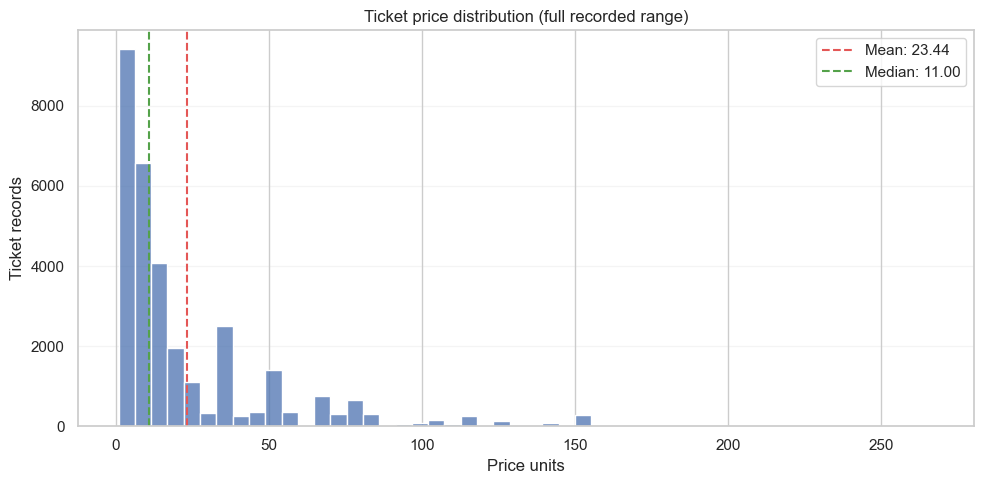

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    data=price.dropna(),
    bins=50,
    binrange=(price.min(), price.max()),
    kde=False,
    ax=ax,
    color=sns.color_palette()[0],
    edgecolor="white",
)
ax.axvline(price.mean(), color="#E45756", linestyle="--", label=f"Mean: {price.mean():.2f}")
ax.axvline(price.median(), color="#54A24A", linestyle="--", label=f"Median: {price.median():.2f}")
ax.set(
    title="Ticket price distribution (full recorded range)",
    xlabel="Price units",
    ylabel="Ticket records",
)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


### Ticket type and class

In [ ]:
mix_summary = (
    df.assign(Price_numeric=price)
    .groupby(["Ticket Type", "Ticket Class"], dropna=False, observed=True)["Price_numeric"]
    .agg(
        Ticket_records="size",
        Usable_prices="count",
        Mean_price="mean",
        Median_price="median",
    )
    .round(2)
)
display(mix_summary)

mean_prices = df.assign(Price_numeric=price).pivot_table(
    index="Ticket Type",
    columns="Ticket Class",
    values="Price_numeric",
    aggfunc="mean",
    observed=True,
)
mean_price_plot = mean_prices.rename_axis("Ticket Type").reset_index().melt(
    id_vars="Ticket Type",
    var_name="Ticket Class",
    value_name="Average price units",
)


Ticket_records  Usable_prices  Mean_price  \
Ticket Type Ticket Class                                              
Advance     First Class             1764           1764       37.92   
            Standard               15797          15797       15.34   
Anytime     First Class              490            490       77.23   
            Standard                4850           4850       35.35   
Off-Peak    First Class              804            804       55.56   
            Standard                7948           7948       22.48   

                          Median_price  
Ticket Type Ticket Class                
Advance     First Class           35.0  
            Standard               8.0  
Anytime     First Class           69.0  
            Standard              16.0  
Off-Peak    First Class           52.0  
            Standard              12.0

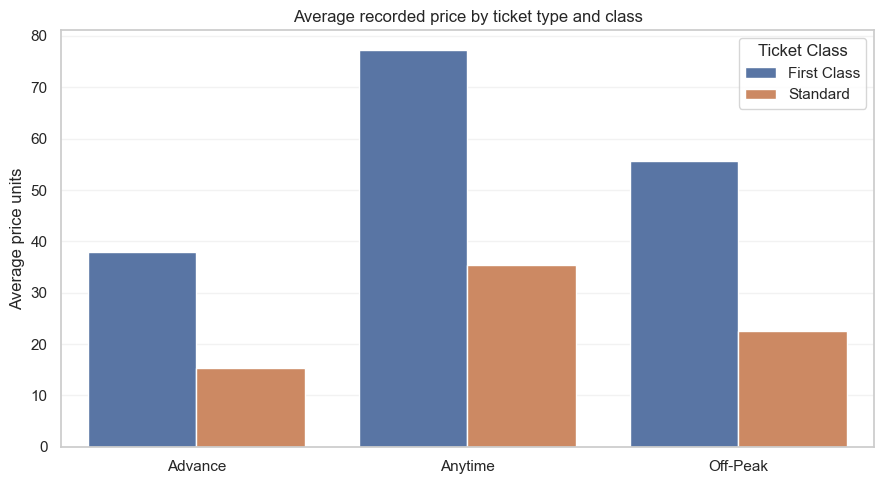

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=mean_price_plot,
    x="Ticket Type",
    y="Average price units",
    hue="Ticket Class",
    order=mean_prices.index.tolist(),
    hue_order=mean_prices.columns.tolist(),
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=ax,
)
ax.set(
    title="Average recorded price by ticket type and class",
    xlabel="",
    ylabel="Average price units",
)
ax.legend(title="Ticket Class")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


### Railcard categories and prices

In [ ]:
railcard_labels = df["Railcard"].replace("", "Blank / unspecified")
railcard_price = pd.DataFrame({"Railcard": railcard_labels, "Price": price})
railcard_summary = (
    railcard_price.groupby("Railcard", dropna=False, observed=True)["Price"]
    .agg(
        Ticket_records="size",
        Usable_prices="count",
        Mean_price="mean",
        Median_price="median",
    )
    .round(2)
)
display(railcard_summary)
railcard_pct = railcard_labels.value_counts(dropna=False, normalize=True).mul(100).sort_values()


,Ticket_records,Usable_prices,Mean_price,Median_price
Railcard,,,,
Adult,4846,4846,17.81,8.0
Disabled,3089,3089,16.92,8.0
None,20918,20918,27.43,13.0
Senior,2800,2800,10.58,4.0


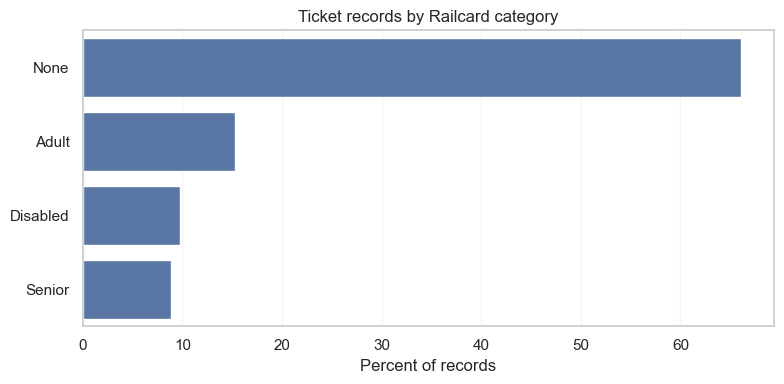

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=railcard_pct.to_numpy(),
    y=railcard_pct.index,
    order=railcard_pct.index.tolist()[::-1],
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=ax,
    color=sns.color_palette()[0],
)
ax.set(
    title="Ticket records by Railcard category",
    xlabel="Percent of records",
    ylabel="",
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


Group price differences are descriptive and do not establish a causal discount effect.

## 4. Purchase channels and payment methods

In [ ]:
purchase_payment_counts = pd.crosstab(df["Purchase Type"], df["Payment Method"])
purchase_payment_pct = purchase_payment_counts.div(
    purchase_payment_counts.sum(axis=1), axis=0
).mul(100).round(1)
print("Purchase-channel and payment-method counts:")
display(purchase_payment_counts)
print("Payment-method percentages within each purchase channel:")
display(purchase_payment_pct)

purchase_type_counts = df["Purchase Type"].value_counts(dropna=False)
purchase_type_pct = (
    purchase_type_counts / purchase_type_counts.sum() * 100
).sort_values()
payment_method_counts = df["Payment Method"].value_counts(dropna=False)
payment_method_pct = (
    payment_method_counts / payment_method_counts.sum() * 100
).sort_values()


Purchase-channel and payment-method counts:


Payment Method,Contactless,Credit Card,Debit Card
Purchase Type,,,
Online,6390,11487,644
Station,4444,7649,1039


Payment-method percentages within each purchase channel:


Payment Method,Contactless,Credit Card,Debit Card
Purchase Type,,,
Online,34.5,62.0,3.5
Station,33.8,58.2,7.9


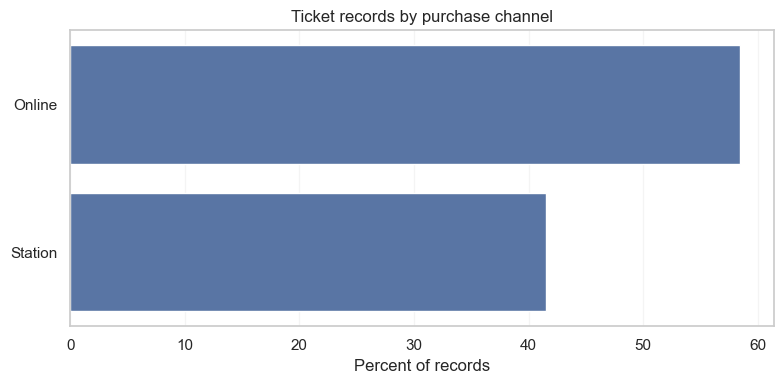

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=purchase_type_pct.to_numpy(),
    y=purchase_type_pct.index,
    order=purchase_type_pct.index.tolist()[::-1],
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=ax,
    color=sns.color_palette()[0],
)
ax.set(title="Ticket records by purchase channel", xlabel="Percent of records", ylabel="")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


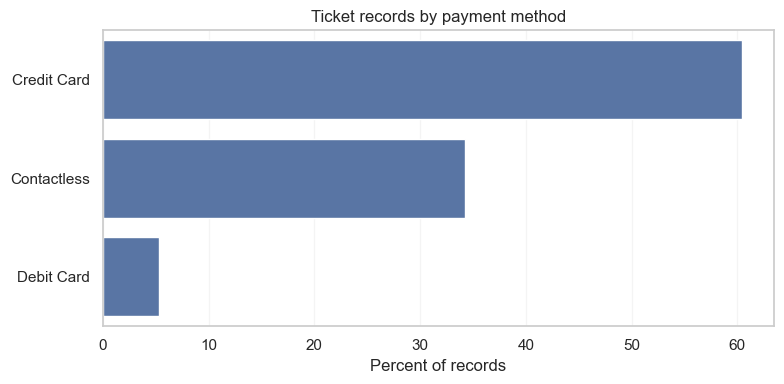

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=payment_method_pct.to_numpy(),
    y=payment_method_pct.index,
    order=payment_method_pct.index.tolist()[::-1],
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=ax,
    color=sns.color_palette()[0],
)
ax.set(title="Ticket records by payment method", xlabel="Percent of records", ylabel="")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


## 5. Routes and ticket-sales value

In [ ]:
route_frame = pd.DataFrame({
    "Departure": df["Departure Station"],
    "Arrival": df["Arrival Destination"],
    "Price": price,
})
route_summary = (
    route_frame.groupby(["Departure", "Arrival"], dropna=False, observed=True)
    .agg(
        Ticket_records=("Price", "size"),
        Usable_prices=("Price", "count"),
        Ticket_sales_value=("Price", lambda values: values.sum(min_count=1)),
        Mean_price=("Price", "mean"),
    )
    .sort_values("Ticket_sales_value", ascending=False)
)
display(route_summary.head(10).round(2))
top_routes = route_summary.head(10).sort_values("Ticket_sales_value")
route_labels = [f"{departure} to {arrival}" for departure, arrival in top_routes.index]


,,Ticket_records,Usable_prices,Ticket_sales_value,Mean_price
Departure,Arrival,,,,
London Kings Cross,York,3922,3922,183193,46.71
Liverpool Lime Street,London Euston,1097,1097,113299,103.28
London Paddington,Reading,3873,3873,65368,16.88
London Euston,Manchester Piccadilly,712,712,61004,85.68
London St Pancras,Birmingham New Street,3471,3471,52869,15.23
London Euston,Birmingham New Street,4209,4209,50349,11.96
Manchester Piccadilly,London Euston,345,345,33860,98.14
Birmingham New Street,London St Pancras,702,702,19011,27.08
Manchester Piccadilly,Liverpool Lime Street,4628,4628,17310,3.74


A route with records but no usable prices has an unavailable sales value, not zero.

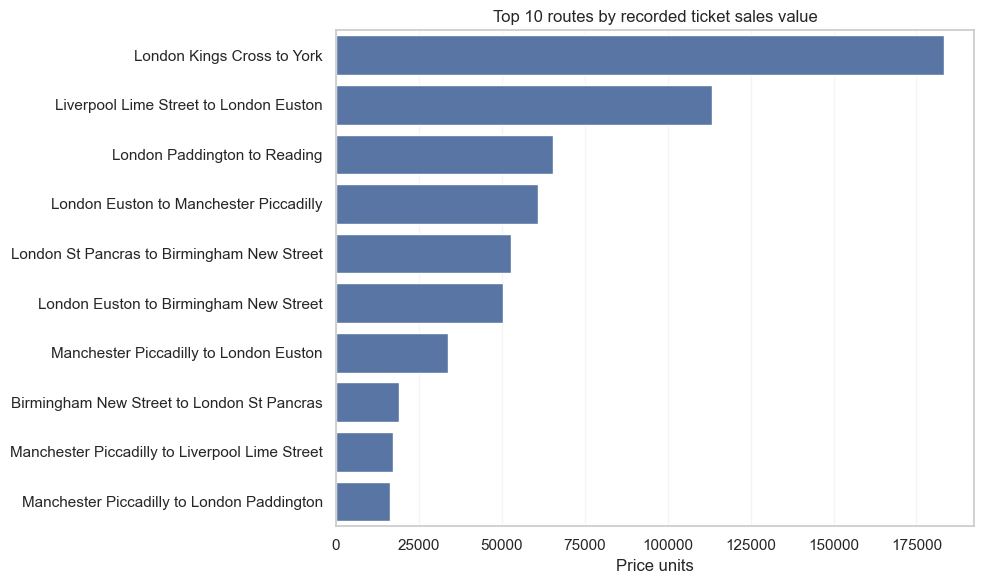

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=top_routes["Ticket_sales_value"].to_numpy(),
    y=route_labels,
    order=route_labels[::-1],
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=ax,
    color=sns.color_palette()[0],
)
ax.set(
    title="Top 10 routes by recorded ticket sales value",
    xlabel="Price units",
    ylabel="",
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


## 6. Purchase-date daily and monthly activity

### Daily purchase-date activity

In [ ]:
purchase_frame = pd.DataFrame({"Date": purchase_date, "Price": price}).dropna(subset=["Date"])
if purchase_frame.empty:
    raise ValueError("There are no valid purchase dates to summarize.")

calendar = pd.date_range(
    purchase_frame["Date"].min(),
    purchase_frame["Date"].max(),
    freq="D",
    name="Date",
)
daily_records = purchase_frame.groupby("Date").size().reindex(calendar, fill_value=0).astype(int)
daily_sales = purchase_frame.groupby("Date")["Price"].sum(min_count=1).reindex(calendar)

daily_sales = daily_sales.mask(daily_records.eq(0), 0)
daily_summary = pd.DataFrame({
    "Ticket_records": daily_records,
    "Ticket_sales_value": daily_sales,
})
print(f"Purchase-date ticket records: {daily_records.sum():,}")
display(daily_summary.head(10))


Purchase-date ticket records: 31,653


,Ticket_records,Ticket_sales_value
Date,,
2023-12-08,1,43.0
2023-12-09,0,0.0
2023-12-10,0,0.0
2023-12-11,0,0.0
2023-12-12,0,0.0
2023-12-13,0,0.0
2023-12-14,0,0.0
2023-12-15,0,0.0
2023-12-16,1,23.0


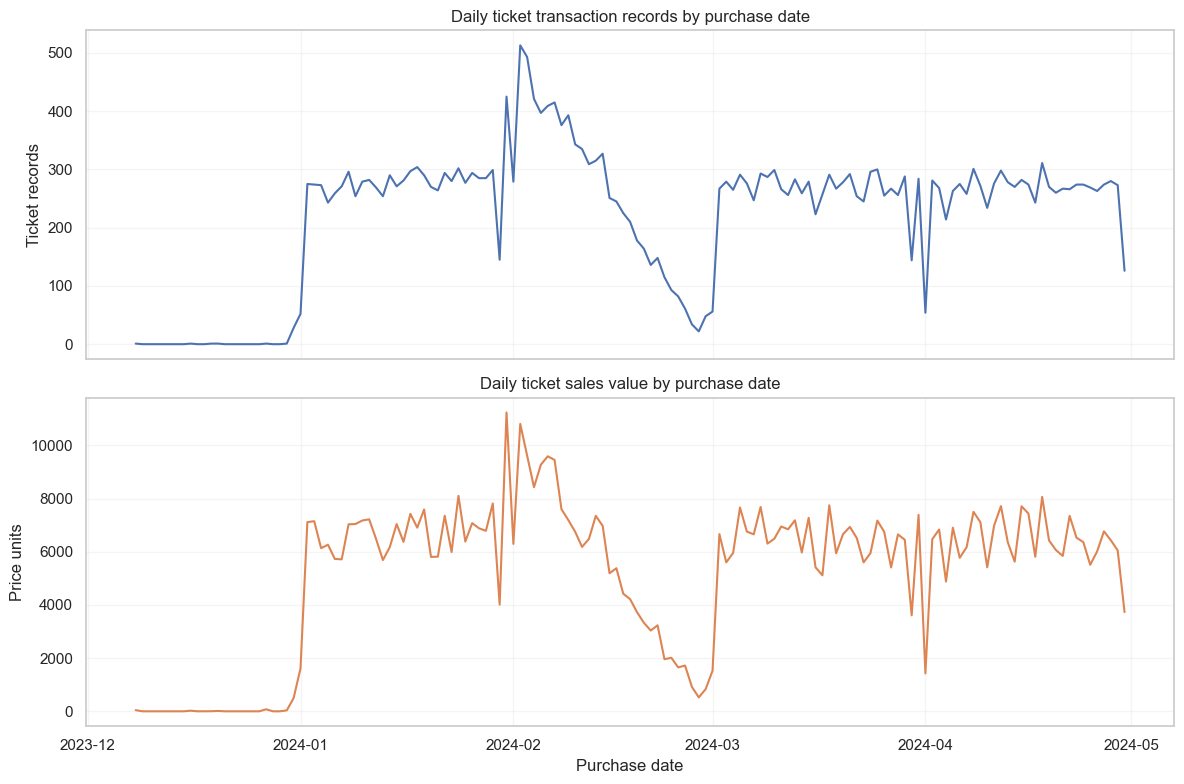

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.lineplot(
    x=daily_records.index,
    y=daily_records.to_numpy(),
    estimator=None,
    errorbar=None,
    sort=True,
    ax=axes[0],
    color=sns.color_palette()[0],
)
axes[0].set(
    title="Daily ticket transaction records by purchase date",
    ylabel="Ticket records",
)
sns.lineplot(
    x=daily_sales.index,
    y=daily_sales.to_numpy(dtype=float),
    estimator=None,
    errorbar=None,
    sort=True,
    ax=axes[1],
    color=sns.color_palette()[1],
)
axes[1].set(
    title="Daily ticket sales value by purchase date",
    ylabel="Price units",
    xlabel="Purchase date",
)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


Dates without ticket records have zero sales value; dates with records but unusable prices remain unavailable.

### Monthly purchase-date activity

In [ ]:
monthly_records = daily_records.groupby(daily_records.index.to_period("M")).sum()
monthly_sales = daily_sales.groupby(daily_sales.index.to_period("M")).sum(min_count=1)
monthly_summary = pd.DataFrame({
    "Ticket_records": monthly_records,
    "Ticket_sales_value": monthly_sales,
})
months = monthly_records.index.astype(str).tolist()
display(monthly_summary)
print("Zero-record dates:", int(daily_records.eq(0).sum()))
print("Dates with records but no usable prices:", int((daily_records.gt(0) & daily_sales.isna()).sum()))


,Ticket_records,Ticket_sales_value
Date,,
2023-12,34,692.0
2024-01,8434,205091.0
2024-02,7337,154118.0
2024-03,8100,194789.0
2024-04,7748,187231.0


Zero-record dates: 17
Dates with records but no usable prices: 0


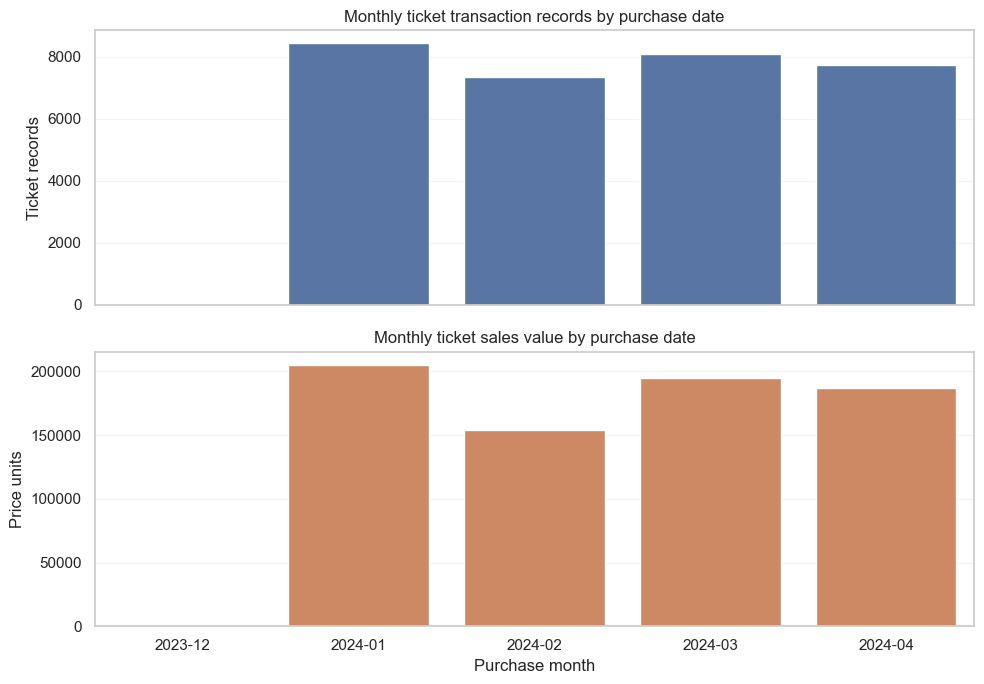

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
sns.barplot(
    x=months,
    y=monthly_records.to_numpy(),
    order=months,
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=axes[0],
    color=sns.color_palette()[0],
)
axes[0].set(
    title="Monthly ticket transaction records by purchase date",
    ylabel="Ticket records",
)
sns.barplot(
    x=months,
    y=monthly_sales.to_numpy(dtype=float),
    order=months,
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=axes[1],
    color=sns.color_palette()[1],
)
axes[1].set(
    title="Monthly ticket sales value by purchase date",
    ylabel="Price units",
    xlabel="Purchase month",
)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


## 7. Journey-date activity

In [ ]:
journey_frame = pd.DataFrame({
    "Date": journey_date,
    "Journey Status": df["Journey Status"],
}).dropna(subset=["Date"])
journey_calendar = pd.date_range(
    journey_frame["Date"].min(),
    journey_frame["Date"].max(),
    freq="D",
    name="Date",
)
journey_daily = journey_frame.groupby("Date").size().reindex(journey_calendar, fill_value=0).astype(int)
journey_monthly = journey_frame.groupby(journey_frame["Date"].dt.to_period("M")).size()
journey_monthly = journey_monthly.reindex(
    pd.period_range(journey_monthly.index.min(), journey_monthly.index.max(), freq="M"),
    fill_value=0,
)
display(pd.DataFrame({"Journey-date ticket records": journey_monthly}))

status_counts = df["Journey Status"].value_counts(dropna=False)
status_pct = (status_counts / status_counts.sum() * 100).round(2)
display(pd.DataFrame({"Ticket records": status_counts, "Percent": status_pct}))


,Journey-date ticket records
2024-01,8111
2024-02,7644
2024-03,8117
2024-04,7781


,Ticket records,Percent
Journey Status,,
On Time,27481,86.82
Delayed,2292,7.24
Cancelled,1880,5.94


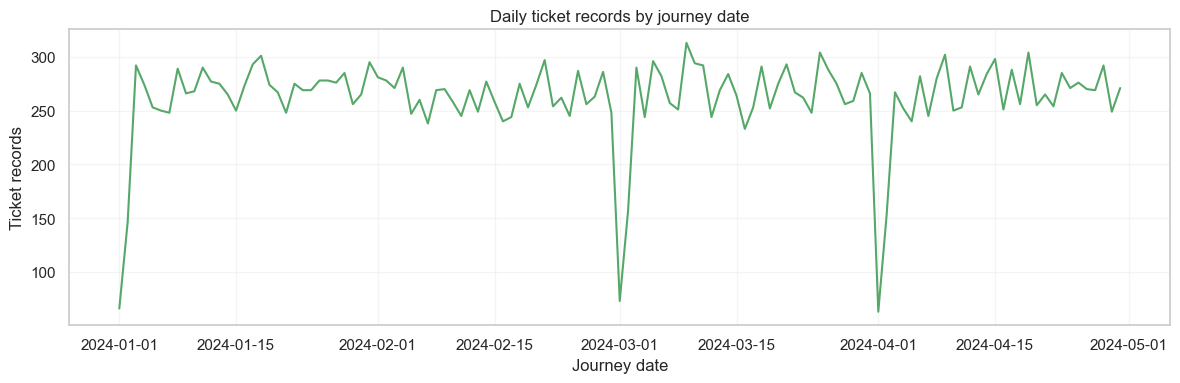

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(
    x=journey_daily.index,
    y=journey_daily.to_numpy(),
    estimator=None,
    errorbar=None,
    sort=True,
    ax=ax,
    color=sns.color_palette()[2],
)
ax.set(
    title="Daily ticket records by journey date",
    xlabel="Journey date",
    ylabel="Ticket records",
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


## 8. Journey reliability, disruption reasons, and refund requests

### Delay and cancellation reasons

In [ ]:
status_order = ["On Time", "Delayed", "Cancelled"]
reason_counts = (
    df.loc[df["Journey Status"].isin(["Delayed", "Cancelled"]), "Reason for Delay"]
    .value_counts(dropna=False)
    .rename_axis("Recorded reason")
    .to_frame("Ticket records")
)
display(reason_counts)


,Ticket records
Recorded reason,
Weather,995
Technical Issue,707
Signal Failure,523
Signal failure,447
Staffing,410
Staff Shortage,399
Weather Conditions,377
Traffic,314


### Refund requests by journey status

In [ ]:
refund_counts = pd.crosstab(df["Journey Status"], df["Refund Request"]).reindex(status_order)
refund_pct = refund_counts.div(refund_counts.sum(axis=1), axis=0).mul(100).round(2)
refund_yes = refund_pct.get("Yes", pd.Series(dtype=float)).reindex(status_order)
print("Refund request counts by journey status:")
display(refund_counts)
print("Refund request percentages within each journey status:")
display(refund_pct)


Refund request counts by journey status:


Refund Request,No,Yes
Journey Status,,
On Time,27481,0
Delayed,1746,546
Cancelled,1308,572


Refund request percentages within each journey status:


Refund Request,No,Yes
Journey Status,,
On Time,100.00,0.00
Delayed,76.18,23.82
Cancelled,69.57,30.43


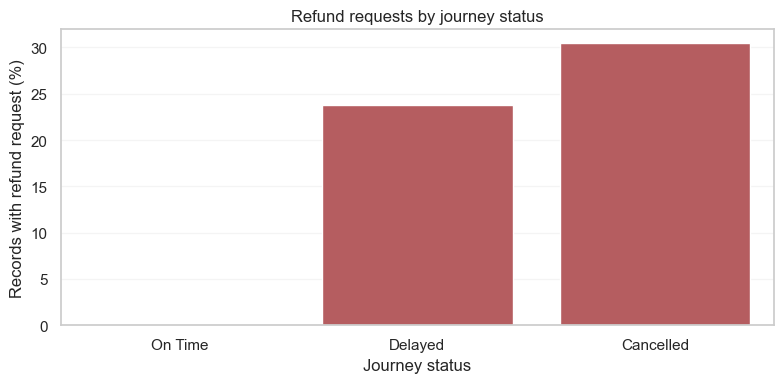

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=refund_yes.index,
    y=refund_yes.to_numpy(dtype=float),
    order=status_order,
    estimator=lambda values: np.asarray(values)[0],
    errorbar=None,
    ax=ax,
    color=sns.color_palette()[3],
)
ax.set(
    title="Refund requests by journey status",
    xlabel="Journey status",
    ylabel="Records with refund request (%)",
)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


Refund percentages use each status as the denominator. A request does not confirm that a refund was paid.

## 9. Data-quality findings and review flags

In [ ]:
print("Empty actual-arrival times by status:")
actual_arrival_blanks = (
    df.assign(Empty=df["Actual Arrival Time"].eq(""))
    .groupby("Journey Status", observed=True)["Empty"]
    .sum()
    .to_frame("Empty actual arrival times")
)
display(actual_arrival_blanks)

print("Empty delay reasons by status:")
delay_reason_blanks = (
    df.assign(Empty=df["Reason for Delay"].eq(""))
    .groupby("Journey Status", observed=True)["Empty"]
    .sum()
    .to_frame("Empty delay reasons")
)
display(delay_reason_blanks)

departure_dt = pd.to_datetime(
    df["Date of Journey"] + " " + df["Departure Time"],
    errors="coerce",
)
scheduled_dt = pd.to_datetime(
    df["Date of Journey"] + " " + df["Arrival Time"],
    errors="coerce",
)
actual_dt = pd.to_datetime(
    (df["Date of Journey"] + " " + df["Actual Arrival Time"]).where(
        df["Actual Arrival Time"].ne("")
    ),
    errors="coerce",
)
scheduled_overnight = scheduled_dt.lt(departure_dt).fillna(False).astype(int)
actual_overnight = actual_dt.lt(departure_dt).fillna(False).astype(int)
scheduled_dt = scheduled_dt + pd.to_timedelta(scheduled_overnight, unit="D")
actual_dt = actual_dt + pd.to_timedelta(actual_overnight, unit="D")
delay_minutes = (actual_dt - scheduled_dt).dt.total_seconds() / 60
status_time_disagreement = (
    df["Journey Status"].eq("Delayed") & delay_minutes.le(0)
).fillna(False)

print("Overnight assumption: add one day when arrival clock time is earlier than departure.")
print(f"Records with usable arrival times: {int(delay_minutes.notna().sum()):,}")
print(f"Delayed records arriving on time or earlier: {int(status_time_disagreement.sum())}")
print(f"Maximum recorded price: {price.max():.2f} price units; high prices are review flags, not confirmed errors.")
print("Recorded text categories to review:")
for column in ["Reason for Delay", "Payment Method", "Journey Status"]:
    print(column, sorted(value for value in df[column].unique() if value != ""))


Empty actual-arrival times by status:


,Empty actual arrival times
Journey Status,
Cancelled,1880
Delayed,0
On Time,0


Empty delay reasons by status:


,Empty delay reasons
Journey Status,
Cancelled,0
Delayed,0
On Time,27481


Overnight assumption: add one day when arrival clock time is earlier than departure.
Records with usable arrival times: 29,773
Delayed records arriving on time or earlier: 18
Maximum recorded price: 267.00 price units; high prices are review flags, not confirmed errors.
Recorded text categories to review:
Reason for Delay ['Signal Failure', 'Signal failure', 'Staff Shortage', 'Staffing', 'Technical Issue', 'Traffic', 'Weather', 'Weather Conditions']
Payment Method ['Contactless', 'Credit Card', 'Debit Card']
Journey Status ['Cancelled', 'Delayed', 'On Time']


Using the overnight assumption (add a day when arrival time is earlier than departure), 18 records marked Delayed have actual arrival at or before scheduled arrival. Their status remains unchanged. High prices and expected blanks are review flags, not confirmed errors.

## 10. Reconciliation checks

In [ ]:
route_record_total = int(route_summary["Ticket_records"].sum())
monthly_purchase_record_total = int(monthly_records.sum())
journey_record_total = int(journey_frame.shape[0])
print(f"Source ticket records: {len(df):,}")
print(f"Route record total: {route_record_total:,} | reconciles: {route_record_total == len(df)}")
print(
    f"Daily purchase record total: {int(daily_records.sum()):,} | "
    f"reconciles: {int(daily_records.sum()) == len(purchase_frame)}"
)
print(
    f"Monthly purchase record total: {monthly_purchase_record_total:,} | "
    f"reconciles: {monthly_purchase_record_total == len(purchase_frame)}"
)
print(
    f"Journey-date record total: {journey_record_total:,} | "
    f"valid journey dates: {int(journey_date.notna().sum()):,}"
)

overall_sales = price.sum(min_count=1)
route_sales = route_summary["Ticket_sales_value"].sum(min_count=1)
daily_sales_total = daily_sales.sum(min_count=1)
monthly_sales_total = monthly_sales.sum(min_count=1)
print(f"Overall ticket sales value: {overall_sales:,.2f}")
print(
    f"Route total: {route_sales:,.2f} | "
    f"reconciles: {np.isclose(route_sales, overall_sales, equal_nan=True)}"
)
print(
    f"Daily total: {daily_sales_total:,.2f} | "
    f"reconciles: {np.isclose(daily_sales_total, overall_sales, equal_nan=True)}"
)
print(
    f"Monthly total: {monthly_sales_total:,.2f} | "
    f"reconciles: {np.isclose(monthly_sales_total, overall_sales, equal_nan=True)}"
)
print("Category totals:")
for column in [
    "Railcard",
    "Ticket Type",
    "Ticket Class",
    "Purchase Type",
    "Payment Method",
    "Journey Status",
    "Refund Request",
]:
    total = int(df[column].value_counts(dropna=False).sum())
    print(f"{column}: {total:,} records")


Source ticket records: 31,653
Route record total: 31,653 | reconciles: True
Daily purchase record total: 31,653 | reconciles: True
Monthly purchase record total: 31,653 | reconciles: True
Journey-date record total: 31,653 | valid journey dates: 31,653
Overall ticket sales value: 741,921.00
Route total: 741,921.00 | reconciles: True
Daily total: 741,921.00 | reconciles: True
Monthly total: 741,921.00 | reconciles: True
Category totals:
Railcard: 31,653 records
Ticket Type: 31,653 records
Ticket Class: 31,653 records
Purchase Type: 31,653 records
Payment Method: 31,653 records
Journey Status: 31,653 records
Refund Request: 31,653 records
